# 03. Evaluación final independiente en TEST — ResNet50 FT_D1_PHOTO

Proyecto: diferenciación de defectos superficiales de palta Hass mediante visión artificial y aprendizaje profundo.  
Clases: PICADURA y RUSSET.  
Modelo seleccionado antes de TEST: `FT_D1_PHOTO_s42_01`, elegido por Macro-F1 en *validation*.  
Objetivo: medir una sola vez su capacidad de generalización sobre las 126 imágenes elegibles de test, sin entrenar ni ajustar parámetros.

> Estado inicial: TEST BLOQUEADO. Este notebook está preparado para ser revisado paso a paso. No realiza inferencia en test a menos que se autorice explícitamente en la sección 6. Las imágenes TIFF y los resultados de entrenamiento nunca se modifican.

Ubicación: guardar este archivo como `6. entrenamiento/03_Evaluacion_Final_Test.ipynb`. Abrir en VS Code, WSL: Ubuntu, con el kernel `palta_gpu (CUDA)`. No usar `Run All`.

## 1. Protocolo fijado antes de evaluar TEST

| Parámetro | Valor congelado |
|---|---|
| Condición | FT_D1_PHOTO_s42_01 |
| Checkpoint | `mejor_finetune.weights.h5` de FT_D1_PHOTO |
| Criterio de selección | Macro-F1 de validation = 0.7876 |
| Datos de entrenamiento | 572 TIFF elegibles + 77 copias RUSSET (D1) |
| Transformaciones adicionales | Brillo y contraste 0.95–1.05, solo al entrenar ambas clases |
| Resolución y orden de vistas | 256 × 512, TIFF completo sin dividir, sin volteos |
| Inferencia final | RGB 0–255 → ajuste de tamaño con relleno → ResNet50 con `preprocess_input` interno |
| Regla de clasificación | `argmax` del softmax, sin cambiar umbrales |
| Datos TEST | 126 TIFF elegibles después de las exclusiones auditadas |
| Salida | Carpeta nueva bajo `7. resultados/evaluacion_final/` |

Límites: la selección se hizo con validation (127 imágenes; 21 RUSSET). TEST debe evaluarse una sola vez. Si el resultado fuese menor al esperado, se reportará como tal: no se utilizará TEST para retocar el modelo, escoger umbrales ni elegir otro checkpoint. La auditoría de duplicados exactos no demuestra independencia por lote o sesión si faltan identificadores adicionales.

In [1]:
from pathlib import Path, PureWindowsPath
import hashlib
import json
import os
import platform
import sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
from IPython.display import display

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "README.md").is_file()
             and (p / "utilidades_imagenes.py").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra el notebook desde PROYECTO_TI_2 en la ventana WSL: Ubuntu.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from utilidades_imagenes import (
    encontrar_raiz, resolver_dataset, listar_imagenes, crear_dataset_tf
)

RAIZ = encontrar_raiz()
DATASET = resolver_dataset(RAIZ, "../DATASET_PALTA")
SALIDA_ENTRENAMIENTO = RAIZ / "7. resultados" / "entrenamiento"
RUN_SELECCIONADA = "FT_D1_PHOTO_s42_01"
RUN_REFERENCIA = "FT_D1_s42_03"
RUN_ORIGEN = "D1_s42_03"
CARPETA_MODELO = SALIDA_ENTRENAMIENTO / RUN_SELECCIONADA
CARPETA_REFERENCIA = SALIDA_ENTRENAMIENTO / RUN_REFERENCIA
CHECKPOINT = CARPETA_MODELO / "mejor_finetune.weights.h5"
DESTINO = RAIZ / "7. resultados" / "evaluacion_final" / RUN_SELECCIONADA
CLASES = ["PICADURA", "RUSSET"]
TAMANO = (256, 512)
TAMANO_ENTRADA = TAMANO  # firma compatible con construir_modelo original
SEMILLA = 42
N_TEST_ESPERADO = 126

print("Proyecto:", RAIZ)
print("Dataset disponible:", DATASET.is_dir())
print("Python:", sys.executable)
print("Checkpoint esperado:", CHECKPOINT.relative_to(RAIZ))
print("TEST ya evaluado en este destino:", DESTINO.exists())
print("Estado actual: NO se ejecutó TEST.")

Proyecto: /mnt/c/Users/TCI_AUTO/Documents/Maestría UNI/4_2. Proyecto de Invetigación  2/PROYECTO_TI_2
Dataset disponible: True
Python: /home/tci_auto/.venvs/palta_gpu/bin/python
Checkpoint esperado: 7. resultados/entrenamiento/FT_D1_PHOTO_s42_01/mejor_finetune.weights.h5
TEST ya evaluado en este destino: False
Estado actual: NO se ejecutó TEST.


## 2. Verificación del modelo seleccionado

Esta comprobación es de solo lectura. Confirma la condición, las clases, el checkpoint y los resultados de *validation* registrados por el entrenamiento. El modelo no se vuelve a entrenar.

In [2]:
archivos_requeridos = [
    CARPETA_MODELO / "configuracion.json",
    CARPETA_MODELO / "estado.json",
    CARPETA_MODELO / "metricas_validation.json",
    CARPETA_MODELO / "predicciones_validation.csv",
    CARPETA_MODELO / "auditoria.json",
    CHECKPOINT,
    CARPETA_REFERENCIA / "metricas_validation.json",
    SALIDA_ENTRENAMIENTO / RUN_ORIGEN / "configuracion.json",
]
faltantes = [str(p.relative_to(RAIZ)) for p in archivos_requeridos if not p.is_file()]
if faltantes:
    raise FileNotFoundError("Faltan archivos necesarios:\n" + "\n".join(faltantes))

leer_json = lambda ruta: json.loads(Path(ruta).read_text(encoding="utf-8-sig"))
config = leer_json(CARPETA_MODELO / "configuracion.json")
estado_modelo = leer_json(CARPETA_MODELO / "estado.json")
met_val = leer_json(CARPETA_MODELO / "metricas_validation.json")
met_ref = leer_json(CARPETA_REFERENCIA / "metricas_validation.json")
auditoria_modelo = leer_json(CARPETA_MODELO / "auditoria.json")
config_origen = leer_json(SALIDA_ENTRENAMIENTO / RUN_ORIGEN / "configuracion.json")

if (config.get("condicion") != "FT_D1_PHOTO"
        or config.get("nombre_ejecucion") != RUN_SELECCIONADA
        or config.get("origen") != RUN_ORIGEN
        or config.get("referencia") != RUN_REFERENCIA
        or list(config.get("clases", [])) != CLASES
        or tuple(config.get("tamano_entrada", [])) != TAMANO):
    raise RuntimeError("La configuración guardada no coincide con el protocolo seleccionado.")
if estado_modelo.get("estado") != "entrenamiento_completo":
    raise RuntimeError("El entrenamiento del checkpoint no consta como completo.")
if (met_val.get("estado") != "completo"
        or met_val.get("particion") != "validation"
        or met_val.get("nombre_ejecucion") != RUN_SELECCIONADA
        or met_val.get("firma_protocolo") != config.get("firma_protocolo")):
    raise RuntimeError("Las métricas de validation no corresponden al checkpoint fijado.")
if len(config.get("exclusiones", [])) != 4:
    raise RuntimeError("La lista de exclusiones no corresponde al inventario auditado.")

config_sin_firma = {k: v for k, v in config.items() if k != "firma_protocolo"}
firma_calculada = hashlib.sha256(
    json.dumps(config_sin_firma, sort_keys=True).encode("utf-8")
).hexdigest()
if firma_calculada != config["firma_protocolo"]:
    raise RuntimeError("La firma de configuración no coincide con el protocolo guardado.")

protocolo = config["protocolo_comun"]
if (protocolo.get("sha256_dataset") != config_origen["protocolo_comun"]["sha256_dataset"]
        or protocolo.get("sha256_manifiesto") != config_origen["protocolo_comun"]["sha256_manifiesto"]):
    raise RuntimeError("El entrenamiento final no utiliza el inventario de D1.")
if met_ref.get("estado") != "completo" or met_ref.get("particion") != "validation":
    raise RuntimeError("La referencia FT_D1 no está completa.")

print("Modelo fijado:", RUN_SELECCIONADA)
print("Mejor época según val_loss:", estado_modelo.get("mejor_epoca_val_loss"))
print("Checkpoint disponible:", CHECKPOINT.is_file())
display(pd.DataFrame([
    {"condicion": "FT_D1", "accuracy": met_ref["accuracy"], "macro_f1": met_ref["macro_f1"], "recall_russet": met_ref["recall_russet"]},
    {"condicion": "FT_D1_PHOTO", "accuracy": met_val["accuracy"], "macro_f1": met_val["macro_f1"], "recall_russet": met_val["recall_russet"]},
]).round(4))
print("Aún no se realizaron predicciones de test.")

Modelo fijado: FT_D1_PHOTO_s42_01
Mejor época según val_loss: 5
Checkpoint disponible: True


,condicion,accuracy,macro_f1,recall_russet
0,FT_D1,0.874,0.7524,0.5238
1,FT_D1_PHOTO,0.874,0.7876,0.7143


Aún no se realizaron predicciones de test.


## 3. Auditoría de identidad del dataset

Se recupera la misma lógica de auditoría del experimento de entrenamiento: inventario EDA, firma histórica, duplicados exactos por bytes y píxeles, las cuatro exclusiones lógicas y comprobación de SHA-256. Esta sección primero revisa el manifiesto sin inferencia; la lectura exhaustiva de los 829 hashes se hará inmediatamente antes de abrir TEST.

In [3]:
def hash_archivo(ruta):
    calculo = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            calculo.update(bloque)
    return calculo.hexdigest()


def firma_tabla(tabla):
    texto = "\n".join(tabla["archivo"] + ":" + tabla["sha256"])
    return hashlib.sha256(texto.encode()).hexdigest()


def leer_auditoria():
    carpeta = RAIZ / "7. resultados" / "eda"
    resumen = json.loads((carpeta / "eda_resumen.json").read_text(encoding="utf-8-sig"))
    inventario = pd.read_csv(carpeta / "eda_inventario.csv", encoding="utf-8-sig", keep_default_na=False)
    duplicados = pd.read_csv(carpeta / "eda_duplicados.csv", encoding="utf-8-sig", keep_default_na=False)
    columnas = {"archivo", "sha256", "sha_pixeles", "particion", "clase", "imagen", "error"}
    if not columnas.issubset(inventario.columns):
        raise ValueError("El inventario no contiene la auditoria necesaria.")
    if inventario.empty or inventario["archivo"].duplicated().any():
        raise ValueError("El inventario esta vacio o contiene rutas repetidas.")
    if len(inventario) != resumen["archivos"] or len(inventario) != resumen["imagenes"]:
        raise ValueError("Los conteos no coinciden. Revise el EDA.")
    if resumen["corruptas"] or inventario["error"].ne("").any():
        raise ValueError("El EDA registra errores de lectura.")
    if not inventario["imagen"].astype(str).str.lower().isin(["true", "1"]).all():
        raise ValueError("El inventario incluye archivos no reconocidos como imagenes.")
    if firma_tabla(inventario) != resumen["sha256_dataset"]:
        raise ValueError("La firma del inventario no coincide con el resumen.")
    for campo in ("sha256", "sha_pixeles"):
        if not inventario[campo].astype(str).str.fullmatch(r"[0-9a-f]{64}").all():
            raise ValueError(f"Hashes incompletos en {campo}.")
    for registro in inventario.itertuples(index=False):
        ruta = Path(registro.archivo)
        win = PureWindowsPath(registro.archivo)
        if (ruta.is_absolute() or win.drive or win.root or ".." in ruta.parts
                or "\\" in registro.archivo or len(ruta.parts) < 3):
            raise ValueError("El inventario debe usar rutas relativas dentro del dataset.")
        if ruta.parts[:2] != (registro.particion, registro.clase):
            raise ValueError(f"Ruta y etiqueta incoherentes: {registro.archivo}")
        if registro.particion not in {"train", "validation", "test"}:
            raise ValueError("Particion no reconocida.")
        if registro.clase not in {"PICADURA", "RUSSET"}:
            raise ValueError("Clase no reconocida.")

    requeridas = {"tipo", "archivo", "archivo_coincidente", "particion",
                  "particion_coincidente", "clase", "clase_coincidente"}
    if not requeridas.issubset(duplicados.columns):
        raise ValueError("El reporte de duplicados esta incompleto.")
    exactos = duplicados[duplicados["tipo"].isin(["bytes_exactos", "pixeles_exactos"])]
    indexado = inventario.set_index("archivo")
    pares_fuga, pares_conflicto, excluidos = set(), set(), set()
    for fila in exactos.itertuples(index=False):
        a, b = fila.archivo, fila.archivo_coincidente
        if a == b or a not in indexado.index or b not in indexado.index:
            raise ValueError("El reporte de duplicados contiene una ruta invalida.")
        ra, rb = indexado.loc[a], indexado.loc[b]
        if (ra.particion, rb.particion, ra.clase, rb.clase) != (
                fila.particion, fila.particion_coincidente, fila.clase, fila.clase_coincidente):
            raise ValueError("Duplicados e inventario no coinciden.")
        clave = "sha256" if fila.tipo == "bytes_exactos" else "sha_pixeles"
        if ra[clave] != rb[clave]:
            raise ValueError("El par reportado no coincide con los hashes del inventario.")
        par = tuple(sorted([a, b]))
        fuga, conflicto = ra.particion != rb.particion, ra.clase != rb.clase
        if fuga:
            pares_fuga.add(par)
        if conflicto:
            pares_conflicto.add(par)
        if fuga or conflicto:
            excluidos.update([a, b])
    if (len(pares_fuga) != resumen["pares_exactos_entre_particiones"]
            or len(pares_conflicto) != resumen["pares_exactos_etiquetas_distintas"]):
        raise ValueError("Los conteos de pares no coinciden con el resumen.")

    elegibles = inventario.loc[~inventario["archivo"].isin(excluidos)].copy()
    for clave in ("sha256", "sha_pixeles"):
        grupos = elegibles.groupby(clave)[["particion", "clase"]].nunique()
        if (grupos > 1).any().any():
            raise ValueError("Persisten duplicados entre particiones o clases. Revise el EDA.")
    return resumen, inventario, sorted(excluidos)


def verificar_auditoria(dataset, aprobar_exclusiones=False):
    resumen, inventario, excluidos = leer_auditoria()
    dataset = Path(dataset).resolve()
    rutas = set(inventario["archivo"])
    locales = {p.relative_to(dataset).as_posix() for p in dataset.rglob("*") if p.is_file()}
    if locales != rutas:
        raise RuntimeError("El contenido del dataset cambio. Revise las rutas y actualice el EDA.")
    total = len(inventario)
    for numero, registro in enumerate(inventario.itertuples(index=False), 1):
        ruta = (dataset / registro.archivo).resolve()
        if not ruta.is_relative_to(dataset):
            raise ValueError("Un enlace apunta fuera del dataset.")
        if hash_archivo(ruta) != registro.sha256:
            raise RuntimeError(f"Archivo distinto al auditado: {registro.archivo}")
        if numero % 100 == 0 or numero == total:
            print(f"Integridad: {numero}/{total}")
    if excluidos and not aprobar_exclusiones:
        raise RuntimeError(
            "Integridad correcta; falta aprobar las exclusiones mostradas en la seccion 8. "
            "No se entreno ni se modificaron imagenes."
        )
    elegibles = inventario.loc[~inventario["archivo"].isin(excluidos)].sort_values("archivo")
    return {
        "sha256_dataset": resumen["sha256_dataset"],
        "sha256_manifiesto": firma_tabla(elegibles),
        "exclusiones": excluidos,
        "archivos_originales": int(len(inventario)),
        "archivos_elegibles": int(len(elegibles)),
        "alcance": "Integridad exacta; independencia por fruto/lote pendiente de trazabilidad.",
    }

In [4]:
resumen_eda, inventario_eda, excluidos_eda = leer_auditoria()
if resumen_eda["sha256_dataset"] != protocolo["sha256_dataset"]:
    raise RuntimeError("Firma histórica del dataset distinta a la del entrenamiento.")
if sorted(excluidos_eda) != sorted(config["exclusiones"]):
    raise RuntimeError("Las exclusiones no coinciden con las aplicadas al entrenamiento.")

tabla_test = listar_imagenes(DATASET, "test", clases=CLASES)
tabla_test = tabla_test.loc[~tabla_test["archivo"].isin(excluidos_eda)].reset_index(drop=True)
if len(tabla_test) != N_TEST_ESPERADO:
    raise RuntimeError(f"TEST debería contener {N_TEST_ESPERADO} imágenes elegibles; hay {len(tabla_test)}.")
if tabla_test["archivo"].duplicated().any() or set(tabla_test["clase"]) != set(CLASES):
    raise RuntimeError("Se encontraron duplicados de ruta o falta una clase en TEST.")
if tabla_test["etiqueta"].to_numpy().dtype.kind not in "iu":
    raise RuntimeError("Las etiquetas de TEST no son enteras.")

print("Archivos originales del inventario:", len(inventario_eda))
print("Exclusiones históricas:", len(excluidos_eda))
print("Elegibles globales:", len(inventario_eda) - len(excluidos_eda))
print("Elegibles en TEST:", len(tabla_test))
print("Distribución de TEST (sin inferencia):")
display(tabla_test["clase"].value_counts().reindex(CLASES, fill_value=0).rename("n_imagenes").to_frame())
print("Firma del inventario: correcta. SHA-256 local pendiente para el paso final.")

Archivos originales del inventario: 829
Exclusiones históricas: 4
Elegibles globales: 825
Elegibles en TEST: 126
Distribución de TEST (sin inferencia):


,n_imagenes
clase,
PICADURA,106
RUSSET,20


Firma del inventario: correcta. SHA-256 local pendiente para el paso final.


## 4. Reconstruir el modelo y verificar el checkpoint SIN utilizar TEST

La arquitectura es la misma de FT_D1_PHOTO: ResNet50, promedio global, Dropout 0.35 y Dense softmax. `preprocess_input` se aplica una sola vez dentro del modelo. Se inicializa sin descargar pesos externos (`weights=None`) y después se carga todo el checkpoint entrenado. No se usa `fit()`, no se recalculan pesos y se desactiva el entrenamiento en la inferencia.

Antes de TEST se reproducirán las predicciones de validation guardadas. Si difieren o no coincide la clasificación de alguna de las 127 imágenes, el proceso se detendrá.

In [5]:
def construir_modelo(numero_clases, tamano=TAMANO_ENTRADA,
                      volteo_horizontal=False, semilla=SEMILLA, pesos="imagenet"):
    import tensorflow as tf
    from tensorflow.keras.applications.resnet50 import preprocess_input

    if numero_clases < 2:
        raise ValueError("El clasificador necesita al menos dos clases.")
    tf.keras.utils.set_random_seed(semilla)
    entrada = tf.keras.Input(shape=(*tamano, 3), dtype="float32", name="imagen_rgb")
    x = entrada
    if volteo_horizontal:
        x = tf.keras.layers.RandomFlip("horizontal", seed=semilla, name="aumento_train")(x)
    x = tf.keras.layers.Lambda(preprocess_input, name="preprocesamiento_resnet50")(x)
    modelo_base = tf.keras.applications.ResNet50(
        input_shape=(*tamano, 3), include_top=False, weights=pesos, pooling="avg",
    )
    modelo_base.trainable = False
    x = modelo_base(x, training=False)
    x = tf.keras.layers.Dropout(0.35, seed=semilla)(x)
    salida = tf.keras.layers.Dense(
        numero_clases, activation="softmax", name="clase",
        kernel_initializer=tf.keras.initializers.GlorotUniform(seed=semilla),
    )(x)
    modelo = tf.keras.Model(entrada, salida, name="resnet50_palta")
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"],
    )
    return modelo

In [6]:
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score, recall_score

if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError("No se detectó GPU: seleccione el kernel palta_gpu (CUDA) de WSL: Ubuntu.")
print("GPU detectada:", tf.config.list_physical_devices("GPU"))

# Exactamente el mismo modelo: los pesos se cargan del checkpoint completo.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEMILLA)
modelo_final = construir_modelo(
    numero_clases=len(CLASES), tamano=TAMANO,
    volteo_horizontal=False, semilla=SEMILLA, pesos=None,
)
base_modelo = next(capa for capa in modelo_final.layers if isinstance(capa, tf.keras.Model))
base_modelo.trainable = True
for capa in base_modelo.layers:
    capa.trainable = (capa.name.startswith("conv5_") and
                      not isinstance(capa, tf.keras.layers.BatchNormalization))
modelo_final.load_weights(str(CHECKPOINT))
modelo_final.trainable = False

# Huella del archivo: queda documentada y debe permanecer intacta.
SHA_CHECKPOINT = hash_archivo(CHECKPOINT)
print("Checkpoint cargado. SHA-256:", SHA_CHECKPOINT)
print("Capas entrenables durante la evaluación:",
      sum(int(c.trainable) for c in modelo_final.layers))
print("No se realizó entrenamiento ni inferencia en TEST.")

I0000 00:00:1793034102.593072  260623 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793034103.134965  260623 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793034104.887242  260623 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1793034109.924267  260623 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5561 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070 Ti Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6
/home/tci_auto/.venvs/palta_gpu/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(store)


Checkpoint cargado. SHA-256: d273174144bc2b3a9a2835665a38edf028623bd9ef5eabe6c70a068a9032717e
Capas entrenables durante la evaluación: 0
No se realizó entrenamiento ni inferencia en TEST.


In [7]:

# Reproduccion de validation con el checkpoint cargado.
# Esta celda no utiliza imagenes de TEST.

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display

# 1. Recuperar las predicciones historicas

val_guardada = pd.read_csv(
    CARPETA_MODELO / "predicciones_validation.csv"
)

tabla_val = listar_imagenes(
    DATASET,
    "validation",
    clases=CLASES
)

tabla_val = tabla_val.loc[
    ~tabla_val["archivo"].isin(excluidos_eda)
].reset_index(drop=True)

# 2. Verificar cantidad e identidad de las imagenes

if len(tabla_val) != 127 or len(val_guardada) != 127:
    raise RuntimeError(
        "La cantidad de imagenes en validation cambio."
    )

if tabla_val["archivo"].duplicated().any():
    raise RuntimeError(
        "El inventario de validation contiene rutas duplicadas."
    )

if val_guardada["archivo"].duplicated().any():
    raise RuntimeError(
        "Las predicciones historicas contienen rutas duplicadas."
    )

if set(tabla_val["archivo"]) != set(val_guardada["archivo"]):
    raise RuntimeError(
        "Los archivos de validation no coinciden con el registro historico."
    )

val_guardada = (
    val_guardada
    .set_index("archivo")
    .loc[tabla_val["archivo"]]
    .reset_index()
)

if not np.array_equal(
    tabla_val["clase"].to_numpy(),
    val_guardada["clase"].to_numpy()
):
    raise RuntimeError(
        "Las clases de validation no coinciden con el CSV guardado."
    )

# 3. Reproducir las predicciones utilizando el checkpoint

flujo_val = crear_dataset_tf(
    tabla_val,
    DATASET,
    tamano=TAMANO,
    tamano_lote=1,
    entrenamiento=False,
    semilla=SEMILLA
)

prob_val = np.asarray(
    modelo_final.predict(flujo_val, verbose=0)
)

if prob_val.shape != (127, len(CLASES)):
    raise RuntimeError(
        "Las dimensiones de las predicciones son incorrectas."
    )

if not np.isfinite(prob_val).all():
    raise RuntimeError(
        "Se encontraron probabilidades no validas."
    )

pred_val = np.asarray(CLASES)[
    np.argmax(prob_val, axis=1)
]

pred_guardadas = (
    val_guardada["prediccion"].to_numpy()
)

# 4. Comparar probabilidades actuales e historicas

max_diferencia = max(
    float(
        np.max(
            np.abs(
                prob_val[:, j]
                - val_guardada[
                    f"probabilidad_{clase}"
                ].to_numpy(dtype=float)
            )
        )
    )
    for j, clase in enumerate(CLASES)
)

indices_distintos = np.flatnonzero(
    pred_val != pred_guardadas
)

coincidencias = (
    len(pred_val) - len(indices_distintos)
)

reproduccion_exacta = (
    len(indices_distintos) == 0
)

# 5. Analizar discrepancias cercanas al umbral

indice_russet = list(CLASES).index("RUSSET")

p_russet_guardada = val_guardada[
    "probabilidad_RUSSET"
].to_numpy(dtype=float)

p_russet_actual = prob_val[
    :, indice_russet
]

umbral_clasificacion = 0.5
margen_frontera = 0.01
tolerancia_probabilidad = 0.02

cambios_en_frontera = all(
    abs(
        p_russet_guardada[i] - umbral_clasificacion
    ) <= margen_frontera
    and
    abs(
        p_russet_actual[i] - umbral_clasificacion
    ) <= margen_frontera
    for i in indices_distintos
)

# 6. Calcular metricas actuales

accuracy_actual = accuracy_score(
    tabla_val["clase"],
    pred_val
)

macro_f1_actual = f1_score(
    tabla_val["clase"],
    pred_val,
    labels=CLASES,
    average="macro",
    zero_division=0
)

# 7. Comprobar consistencia de los resultados guardados

accuracy_historica = accuracy_score(
    tabla_val["clase"],
    pred_guardadas
)

macro_f1_historica = f1_score(
    tabla_val["clase"],
    pred_guardadas,
    labels=CLASES,
    average="macro",
    zero_division=0
)

metricas_historicas_ok = bool(
    np.isclose(
        accuracy_historica,
        float(met_val["accuracy"]),
        atol=5e-4,
        rtol=0
    )
    and
    np.isclose(
        macro_f1_historica,
        float(met_val["macro_f1"]),
        atol=5e-4,
        rtol=0
    )
)

# 8. Evaluar compatibilidad numerica

reproduccion_ok = bool(
    metricas_historicas_ok
    and max_diferencia <= tolerancia_probabilidad
    and len(indices_distintos) <= 1
    and cambios_en_frontera
)

# 9. Presentar resultados

print("Total de imagenes:", len(pred_val))
print("Clasificaciones coincidentes:", coincidencias)
print("Clasificaciones diferentes:", len(indices_distintos))

print(
    "Mayor diferencia absoluta de probabilidades:",
    round(max_diferencia, 6)
)

print("Reproduccion exacta:", reproduccion_exacta)

print(
    "Metricas historicas consistentes:",
    metricas_historicas_ok
)

print(
    "Compatibilidad numerica aceptada:",
    reproduccion_ok
)

comparacion_metricas = pd.DataFrame({
    "condicion": [
        "Resultado guardado",
        "Checkpoint reproducido"
    ],
    "accuracy": [
        accuracy_historica,
        accuracy_actual
    ],
    "macro_f1": [
        macro_f1_historica,
        macro_f1_actual
    ]
})

display(
    comparacion_metricas.round(4)
)

# 10. Mostrar imagenes con predicciones diferentes

if len(indices_distintos) > 0:

    diagnostico = pd.DataFrame({
        "archivo": val_guardada.iloc[
            indices_distintos
        ]["archivo"].to_numpy(),

        "clase_real": tabla_val.iloc[
            indices_distintos
        ]["clase"].to_numpy(),

        "prediccion_guardada": pred_guardadas[
            indices_distintos
        ],

        "prediccion_actual": pred_val[
            indices_distintos
        ],

        "p_RUSSET_guardada": p_russet_guardada[
            indices_distintos
        ],

        "p_RUSSET_actual": p_russet_actual[
            indices_distintos
        ]
    })

    print(
        "\nImagenes con diferencias de clasificacion:"
    )

    display(diagnostico.round(6))

# 11. Control final

if not reproduccion_ok:
    raise RuntimeError(
        "Detenido: el checkpoint no cumple los criterios "
        "de compatibilidad numerica con validation."
    )

if reproduccion_exacta:
    print(
        "\nCheckpoint reproducido exactamente."
    )
else:
    print(
        "\nCheckpoint compatible dentro de la tolerancia definida."
    )
    print(
        "La reproduccion no fue exacta y debe documentarse."
    )

print(
    "Sin inferencias en TEST. "
    "La evaluacion final continua desactivada."
)


I0000 00:00:1793034443.883906  262110 service.cc:153] XLA service 0x72a13c0656d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793034443.883985  262110 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3070 Ti Laptop GPU, Compute Capability 8.6 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793034443.979828  262110 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793034444.491887  262110 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793034448.900595  262110 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Total de imagenes: 127
Clasificaciones coincidentes: 126
Clasificaciones diferentes: 1
Mayor diferencia absoluta de probabilidades: 0.004967
Reproduccion exacta: False
Metricas historicas consistentes: True
Compatibilidad numerica aceptada: True


,condicion,accuracy,macro_f1
0,Resultado guardado,0.8740,0.7876
1,Checkpoint reproducido,0.8661,0.7781



Imagenes con diferencias de clasificacion:


,archivo,clase_real,prediccion_guardada,prediccion_actual,p_RUSSET_guardada,p_RUSSET_actual
0,validation/PICADURA/704F3E54-260520-113906-2.R...,PICADURA,PICADURA,RUSSET,0.499474,0.502148



Checkpoint compatible dentro de la tolerancia definida.
La reproduccion no fue exacta y debe documentarse.
Sin inferencias en TEST. La evaluacion final continua desactivada.


In [8]:
import numpy as np
import pandas as pd
from IPython.display import display

predicciones_guardadas = val_guardada["prediccion"].to_numpy()

indices = np.where(
    pred_val != predicciones_guardadas
)[0]

print("Total de imágenes:", len(pred_val))
print("Clasificaciones diferentes:", len(indices))
print("Diferencia máxima:", round(max_diferencia, 6))

diagnostico = pd.DataFrame({
    "archivo": val_guardada.iloc[indices]["archivo"].to_numpy(),
    "clase_real": val_guardada.iloc[indices]["clase"].to_numpy(),
    "prediccion_guardada": predicciones_guardadas[indices],
    "prediccion_actual": pred_val[indices],
    "p_RUSSET_guardada": val_guardada.iloc[indices][
        "probabilidad_RUSSET"
    ].to_numpy(),
    "p_RUSSET_actual": prob_val[
        indices, CLASES.index("RUSSET")
    ]
})

display(diagnostico.round(6))

Total de imágenes: 127
Clasificaciones diferentes: 1
Diferencia máxima: 0.004967


,archivo,clase_real,prediccion_guardada,prediccion_actual,p_RUSSET_guardada,p_RUSSET_actual
0,validation/PICADURA/704F3E54-260520-113906-2.R...,PICADURA,PICADURA,RUSSET,0.499474,0.502148


## 5. Función de evaluación final (definición; NO ejecutar TEST aún)

Al autorizarla, esta función verifica los 829 SHA-256 locales y que las exclusiones, la firma y el modelo coincidan; impide sobrescribir resultados previos; registra la huella del checkpoint; ejecuta inferencia en los 126 TIFF completos de TEST sin augmentations; guarda predicciones, métricas, matriz de confusión y un registro de evaluación. Ningún paso entrena el modelo.

Atención: si una evaluación se interrumpe y ya existe la carpeta de salida, no la borres ni repitas la evaluación. Conserva el estado registrado y revisaremos cómo recuperar lo que se haya guardado.

In [8]:
def intervalo_wilson(aciertos, total, z=1.959963984540054):
    """Intervalo aproximado del 95 % para una proporción binomial."""
    if total <= 0:
        return [None, None]
    p = aciertos / total
    den = 1 + z*z / total
    centro = (p + z*z / (2*total)) / den
    radio = z * ((p * (1-p) / total + z*z / (4*total*total))**0.5) / den
    return [float(max(0.0, centro-radio)), float(min(1.0, centro+radio))]


def realizar_evaluacion_test():
    from sklearn.metrics import (
        confusion_matrix, classification_report, balanced_accuracy_score,
        precision_score, recall_score, f1_score, accuracy_score, ConfusionMatrixDisplay,
    )
    import matplotlib.pyplot as plt

    if DESTINO.exists():
        raise FileExistsError(
            "La evaluación final ya tiene carpeta. No se sobrescribe ni se repite TEST: "
            + str(DESTINO)
        )
    if not reproduccion_ok:
        raise RuntimeError("No se verificó el checkpoint usando validation.")
    if hash_archivo(CHECKPOINT) != SHA_CHECKPOINT:
        raise RuntimeError("El archivo de checkpoint cambió después de la verificación.")
    if len(tabla_test) != N_TEST_ESPERADO:
        raise RuntimeError("Cambió el manifiesto de TEST.")

    print("Verificando integridad SHA-256 antes de evaluar TEST ...")
    audit_final = verificar_auditoria(DATASET, aprobar_exclusiones=True)
    if (audit_final["sha256_dataset"] != protocolo["sha256_dataset"]
            or audit_final["sha256_manifiesto"] != protocolo["sha256_manifiesto"]
            or sorted(audit_final["exclusiones"]) != sorted(config["exclusiones"])):
        raise RuntimeError("La integridad/dataset no coincide con el entrenamiento.")
    if int(audit_final["archivos_elegibles"]) != 825:
        raise RuntimeError("El total elegible cambió.")
    actual = listar_imagenes(DATASET, "test", clases=CLASES)
    actual = actual.loc[~actual["archivo"].isin(audit_final["exclusiones"])].reset_index(drop=True)
    if not np.array_equal(actual["archivo"].to_numpy(), tabla_test["archivo"].to_numpy()):
        raise RuntimeError("El manifiesto TEST cambió desde la verificación inicial.")

    # Huellas completas antes de producir una sola predicción de TEST.
    registro = {
        "modelo_seleccionado": RUN_SELECCIONADA,
        "particion": "test",
        "n_test_elegible": len(actual),
        "firma_protocolo": config["firma_protocolo"],
        "sha256_checkpoint": SHA_CHECKPOINT,
        "sha256_dataset": audit_final["sha256_dataset"],
        "sha256_manifiesto": audit_final["sha256_manifiesto"],
        "clases": CLASES, "tamano_entrada": list(TAMANO),
        "regla_prediccion": "argmax_softmax_sin_ajuste_umbral",
        "augmentation_en_test": False,
        "fecha_utc": datetime.now(timezone.utc).isoformat(),
        "python": platform.python_version(),
        "tensorflow": tf.__version__,
    }

    DESTINO.mkdir(parents=True, exist_ok=False)
    (DESTINO / "estado.json").write_text(
        json.dumps({"estado": "iniciado", "particion": "test"}, indent=2),
        encoding="utf-8",
    )
    (DESTINO / "protocolo_evaluacion.json").write_text(
        json.dumps(registro, ensure_ascii=False, indent=2), encoding="utf-8",
    )
    (DESTINO / "auditoria_test.json").write_text(
        json.dumps(audit_final, ensure_ascii=False, indent=2), encoding="utf-8",
    )
    actual.to_csv(DESTINO / "manifiesto_test.csv", index=False)

    try:
        flujo_test = crear_dataset_tf(
            actual, DATASET, tamano=TAMANO, tamano_lote=1,
            entrenamiento=False, semilla=SEMILLA,
        )
        print("Iniciando inferencia única en TEST:", len(actual), "imágenes")
        prob = np.asarray(modelo_final.predict(flujo_test, verbose=1))
        if (prob.shape != (len(actual), len(CLASES))
                or not np.isfinite(prob).all()
                or not np.allclose(prob.sum(axis=1), 1.0, atol=1e-4)):
            raise RuntimeError("Probabilidades de TEST inválidas.")

        y_verdad = actual["etiqueta"].to_numpy(dtype=np.int32)
        y_pred = np.argmax(prob, axis=1).astype(np.int32)
        etiquetas = np.arange(len(CLASES))
        matriz = confusion_matrix(y_verdad, y_pred, labels=etiquetas)
        informe = classification_report(
            y_verdad, y_pred, labels=etiquetas,
            target_names=CLASES, output_dict=True, zero_division=0,
        )
        n_russet = int(np.sum(y_verdad == CLASES.index("RUSSET")))
        tp_russet = int(matriz[1, 1])
        aciertos = int(np.sum(y_verdad == y_pred))
        metricas = {
            "estado": "completo", "particion": "test",
            "modelo": RUN_SELECCIONADA,
            "n_imagenes": int(len(actual)), "clases": CLASES,
            "firma_protocolo": config["firma_protocolo"],
            "sha256_checkpoint": SHA_CHECKPOINT,
            "accuracy": float(accuracy_score(y_verdad, y_pred)),
            "macro_f1": float(f1_score(y_verdad, y_pred, average="macro", zero_division=0)),
            "balanced_accuracy": float(balanced_accuracy_score(y_verdad, y_pred)),
            "precision_russet": float(precision_score(y_verdad, y_pred, pos_label=1, zero_division=0)),
            "recall_russet": float(recall_score(y_verdad, y_pred, pos_label=1, zero_division=0)),
            "f1_russet": float(informe["RUSSET"]["f1-score"]),
            "recall_picadura": float(informe["PICADURA"]["recall"]),
            "aciertos": aciertos,
            "aciertos_russet": tp_russet,
            "n_russet": n_russet,
            "intervalo95_wilson_accuracy": intervalo_wilson(aciertos, len(actual)),
            "intervalo95_wilson_recall_russet": intervalo_wilson(tp_russet, n_russet),
        }

        predicciones = actual[["archivo", "particion", "clase", "etiqueta"]].copy()
        predicciones["prediccion"] = [CLASES[int(i)] for i in y_pred]
        for indice, clase in enumerate(CLASES):
            predicciones[f"probabilidad_{clase}"] = prob[:, indice]
        predicciones["correcto"] = (y_verdad == y_pred)
        predicciones.to_csv(DESTINO / "predicciones_test.csv", index=False)
        pd.DataFrame(informe).transpose().to_csv(DESTINO / "metricas_por_clase_test.csv")
        pd.DataFrame(matriz, index=CLASES, columns=CLASES).to_csv(
            DESTINO / "matriz_confusion_test.csv"
        )
        (DESTINO / "metricas_test.json").write_text(
            json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8",
        )

        fig, ax = plt.subplots(figsize=(6.4, 5.2))
        ConfusionMatrixDisplay(matriz, display_labels=CLASES).plot(ax=ax)
        ax.set_title("FT_D1_PHOTO — TEST (modelo congelado)")
        fig.tight_layout()
        fig.savefig(DESTINO / "matriz_confusion_test.png", dpi=160)
        plt.show()
        plt.close(fig)

        comparacion = pd.DataFrame([
            {"conjunto": "validation", "n": int(met_val.get("n_imagenes", 127)),
             "accuracy": float(met_val["accuracy"]),
             "macro_f1": float(met_val["macro_f1"]),
             "recall_russet": float(met_val["recall_russet"])},
            {"conjunto": "test", "n": int(metricas["n_imagenes"]),
             "accuracy": metricas["accuracy"], "macro_f1": metricas["macro_f1"],
             "recall_russet": metricas["recall_russet"]},
        ])
        comparacion.to_csv(DESTINO / "comparacion_validation_test.csv", index=False)
        (DESTINO / "estado.json").write_text(
            json.dumps({"estado": "completo", "particion": "test",
                        "n_test": len(actual)}, indent=2), encoding="utf-8",
        )
        print("\nEvaluación TEST COMPLETADA, sin entrenamiento.")
        print("Métricas por clase:")
        display(pd.DataFrame(informe).transpose().round(4))
        print("Comparación descriptiva validation / TEST:")
        display(comparacion.round(4))
        print("Archivos guardados en:", DESTINO.relative_to(RAIZ))
        return metricas

    except (Exception, KeyboardInterrupt) as error:
        (DESTINO / "estado.json").write_text(
            json.dumps({"estado": "incompleto", "particion": "test",
                        "detalle": str(error)}, ensure_ascii=False, indent=2),
            encoding="utf-8",
        )
        print("Evaluación interrumpida; conserve la carpeta de salida.")
        raise

## 6. Autorización explícita de la evaluación final

Por defecto no ejecuta TEST. Esta es la única celda que llama a la evaluación. Antes de activarla, deben estar correctas las comprobaciones anteriores, incluida la reproducción de validation (`reproduccion_ok = True`).

Cuando se acuerde ejecutar la evaluación final, cambiar ambos controles a:

```python
AUTORIZAR_EVALUACION_TEST = True
CONFIRMACION_FINAL = "EVALUAR_TEST_126"
```

Tras completarse, volver inmediatamente a `False` y guardar el notebook. Si la carpeta de resultados ya existe, el código se detiene sin sobrescribir ni repetir.

Verificando integridad SHA-256 antes de evaluar TEST ...
Integridad: 100/829
Integridad: 200/829
Integridad: 300/829
Integridad: 400/829
Integridad: 500/829
Integridad: 600/829
Integridad: 700/829
Integridad: 800/829
Integridad: 829/829
Iniciando inferencia única en TEST: 126 imágenes
126/126 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step


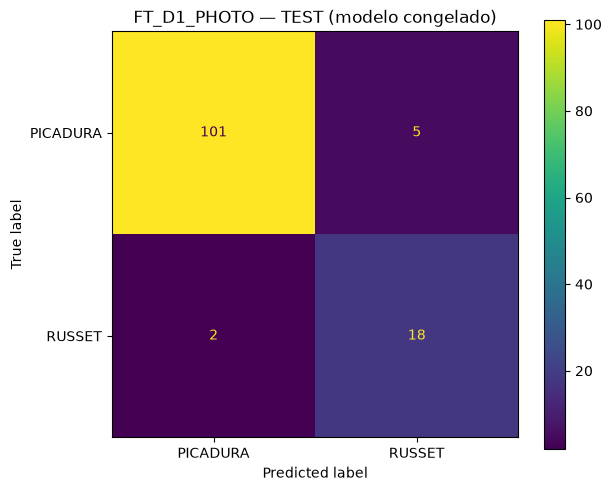


Evaluación TEST COMPLETADA, sin entrenamiento.
Métricas por clase:


,precision,recall,f1-score,support
PICADURA,0.9806,0.9528,0.9665,106.0000
RUSSET,0.7826,0.9000,0.8372,20.0000
accuracy,0.9444,0.9444,0.9444,0.9444
macro avg,0.8816,0.9264,0.9019,126.0000
weighted avg,0.9492,0.9444,0.9460,126.0000


Comparación descriptiva validation / TEST:


,conjunto,n,accuracy,macro_f1,recall_russet
0,validation,127,0.8740,0.7876,0.7143
1,test,126,0.9444,0.9019,0.9000


Archivos guardados en: 7. resultados/evaluacion_final/FT_D1_PHOTO_s42_01
Cambie AUTORIZAR_EVALUACION_TEST = False y guarde con Ctrl+S.


In [ ]:
AUTORIZAR_EVALUACION_TEST = False
CONFIRMACION_FINAL = "NO_EJECUTAR"

if not AUTORIZAR_EVALUACION_TEST:
    print("Modo seguro: TEST no evaluado. Modelo seleccionado:", RUN_SELECCIONADA)
    print("Para la ejecución final, primero revise las verificaciones anteriores.")
elif CONFIRMACION_FINAL != "EVALUAR_TEST_126":
    raise RuntimeError("Falta la confirmación literal EVALUAR_TEST_126.")
else:
    RESULTADO_TEST = realizar_evaluacion_test()
    print("Cambie AUTORIZAR_EVALUACION_TEST = False y guarde con Ctrl+S.")

## 7. Consulta posterior de resultados (solo lectura)

Una vez hecha la evaluación, esta sección muestra métricas ya guardadas sin volver a predecir. No es necesario ejecutarla antes de TEST.

In [ ]:
met_archivo = DESTINO / "metricas_test.json"
est_archivo = DESTINO / "estado.json"
if met_archivo.is_file() and est_archivo.is_file():
    est = leer_json(est_archivo)
    if est.get("estado") != "completo":
        print("La carpeta existe pero la evaluación no figura como completa.")
    else:
        mt = leer_json(met_archivo)
        display(pd.DataFrame([{
            "conjunto": "test", "n": mt["n_imagenes"],
            "accuracy": mt["accuracy"], "macro_f1": mt["macro_f1"],
            "recall_russet": mt["recall_russet"],
        }]).round(4))
        print("Evaluación previamente guardada:", DESTINO.relative_to(RAIZ))
else:
    print("No hay métricas TEST completas; no se inventan ni calculan automáticamente.")

## 8. Interpretación y cierre del proyecto

Después de ejecutar TEST, documentar sin modificar el modelo:

1. Métricas sobre TEST, matriz de confusión, intervalo de Wilson para accuracy y recall RUSSET (interpretarlos como aproximaciones por tamaño reducido).
2. Desempeño de las clases PICADURA y RUSSET, reportando tanto falsas alarmas como defectos omitidos.
3. Diferencias entre validation y TEST como observación de generalización, sin usar TEST como conjunto de selección.
4. Limitaciones: desbalance de clases, pocas muestras RUSSET, origen industrial de las imágenes, posibles dependencias por lote/sesión no demostradas, variación de iluminación y aparente sobreajuste de entrenamiento.
5. Congelar el protocolo y trasladar tablas y figuras a la metodología/resultados del informe de maestría. Si se modifica después el sistema, se requerirá un nuevo conjunto de prueba independiente para su evaluación final.

Evidencias: `metricas_test.json`, `predicciones_test.csv`, `metricas_por_clase_test.csv`, `matriz_confusion_test.csv`, `matriz_confusion_test.png`, `comparacion_validation_test.csv`, `protocolo_evaluacion.json` y `auditoria_test.json` bajo `7. resultados/evaluacion_final/FT_D1_PHOTO_s42_01`.